In [75]:
from HEPiC.utils import data_cleaning as dc
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["font.family"] = "STIXGeneral"
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams["xtick.direction"] = "in"
matplotlib.rcParams["ytick.direction"] = "in"
plt.rcParams['xtick.major.size'] = 2  # Length of major ticks
plt.rcParams['ytick.major.size'] = 2  # Length of major ticks
plt.rcParams['xtick.minor.size'] = 1  # Length of minor ticks
plt.rcParams['ytick.minor.size'] = 1  # Length of minor ticks
import numpy as np

In [52]:
raw_190 = pd.read_csv("L1002-2 1.26.csv")

In [53]:
cleaned_steps, data_clean, step_length = dc.clean_data(raw_190)

inferred step length: 275
number of steps: 100


In [54]:
step_length

275

In [58]:
T_list, fr_list, F_list, D_list = [], [], [], []
for step in cleaned_steps:
    T = step["temperature_C"][int(0.2*step_length):].mean()
    fr = step["feedrate_mms"][int(0.2*step_length):].mean()
    F = step["extrusion_force_N"][int(0.2*step_length):].mean()
    D = step["die_diameter_px"][int(0.2*step_length):].mean()
    if fr < 2:
        continue
    if T == 190:
        T_list.append(T)
        fr_list.append(fr)
        F_list.append(F)
        D_list.append(D)

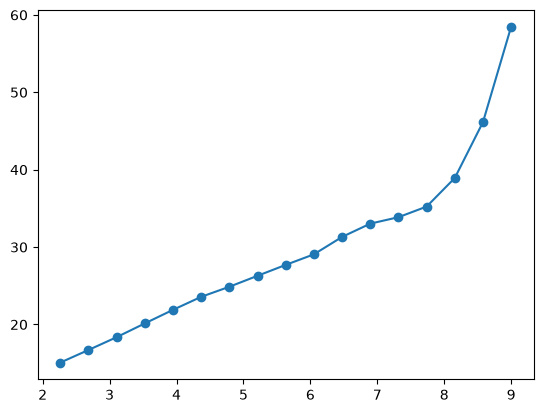

In [56]:
plt.plot(fr_list, F_list, marker='o')

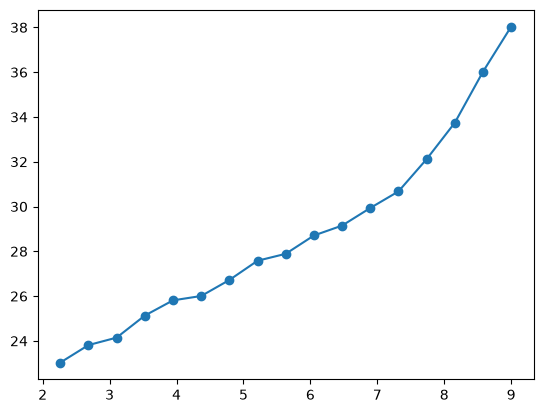

In [59]:
plt.plot(fr_list, D_list, marker='o')

In [57]:
fr_list

[np.float64(2.263166667),
 np.float64(2.684166667),
 np.float64(3.105333333),
 np.float64(3.526333333),
 np.float64(3.9473333330000013),
 np.float64(4.368499999999999),
 np.float64(4.789500000000002),
 np.float64(5.210499999999999),
 np.float64(5.631500000000002),
 np.float64(6.052666667),
 np.float64(6.4736666670000025),
 np.float64(6.894666667),
 np.float64(7.315833333),
 np.float64(7.736833332999997),
 np.float64(8.157833333),
 np.float64(8.579000000000002),
 np.float64(9.0)]

In [43]:
raw_220 = pd.read_csv(r"G:\我的云端硬盘\Polymaker\008.知识产权\挤出力拐点\附图\20261104_140420_pla_0.4.csv")

In [44]:
cleaned_steps, data_clean, step_length = dc.clean_data(raw_220)

inferred step length: 1500
number of steps: 20


In [26]:
cleaned_steps

[      time_s  temperature_C  feedrate_mms  measured_temperature_C  \
 14     0.000          270.0           1.0                  270.03   
 15     0.016          270.0           1.0                  270.03   
 16     0.031          270.0           1.0                  270.03   
 17     0.078          270.0           1.0                  270.03   
 18     0.078          270.0           1.0                  270.03   
 ...      ...            ...           ...                     ...   
 1514  30.000          270.0           1.0                  270.16   
 1515  30.016          270.0           1.0                  270.16   
 1516  30.031          270.0           1.0                  270.16   
 1517  30.078          270.0           1.0                  270.16   
 1518  30.078          270.0           1.0                  270.16   
 
       measured_feedrate_mms  die_diameter_px  die_temperature_C  \
 14                 0.000000        244.19078          207.00000   
 15                 0.

In [54]:
T_list, fr_list, F_list, D_list = [], [], [], []
for step in cleaned_steps:
    T = step["temperature_C"][int(0.2*step_length):].mean()
    fr = step["feedrate_mms"][int(0.2*step_length):].mean()
    F = step["extrusion_force_N"][int(0.2*step_length):].mean()
    D = step["die_diameter_px"][int(0.2*step_length):].mean()
    if fr < 2 or fr > 13:
        continue
    if T == 220:
        T_list.append(T)
        fr_list.append(fr)
        F_list.append(F)
        D_list.append(D)

In [55]:
fr_list

[np.float64(2.368500000000001),
 np.float64(3.0526666666666675),
 np.float64(3.7368333333333323),
 np.float64(4.420999999999999),
 np.float64(5.105333333333333),
 np.float64(5.789500000000003),
 np.float64(6.473666666666666),
 np.float64(7.157833333333333),
 np.float64(7.842166666666665),
 np.float64(8.526333333333334),
 np.float64(9.210499999999998),
 np.float64(9.894666666666668),
 np.float64(10.579000000000002),
 np.float64(11.263166666666667),
 np.float64(11.947333333333331),
 np.float64(12.6315)]

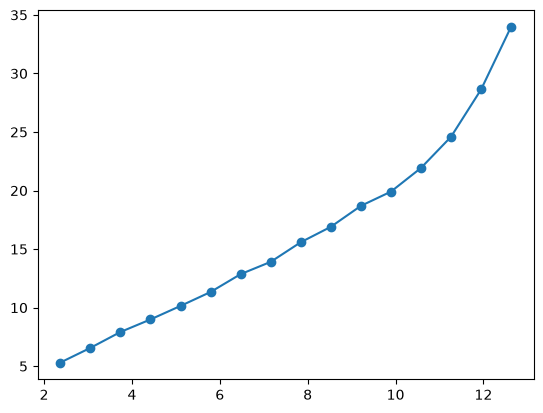

In [56]:
plt.plot(fr_list, F_list, marker='o')

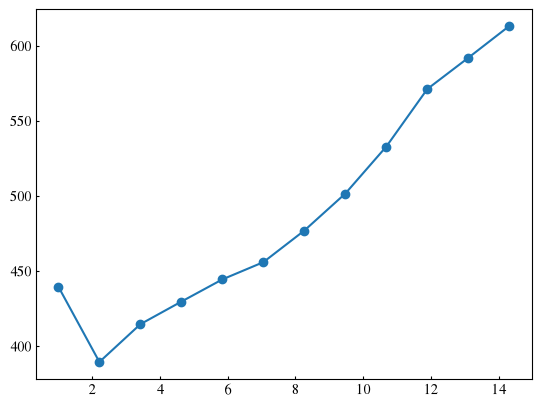

In [88]:
plt.plot(fr_list, D_list, marker='o')

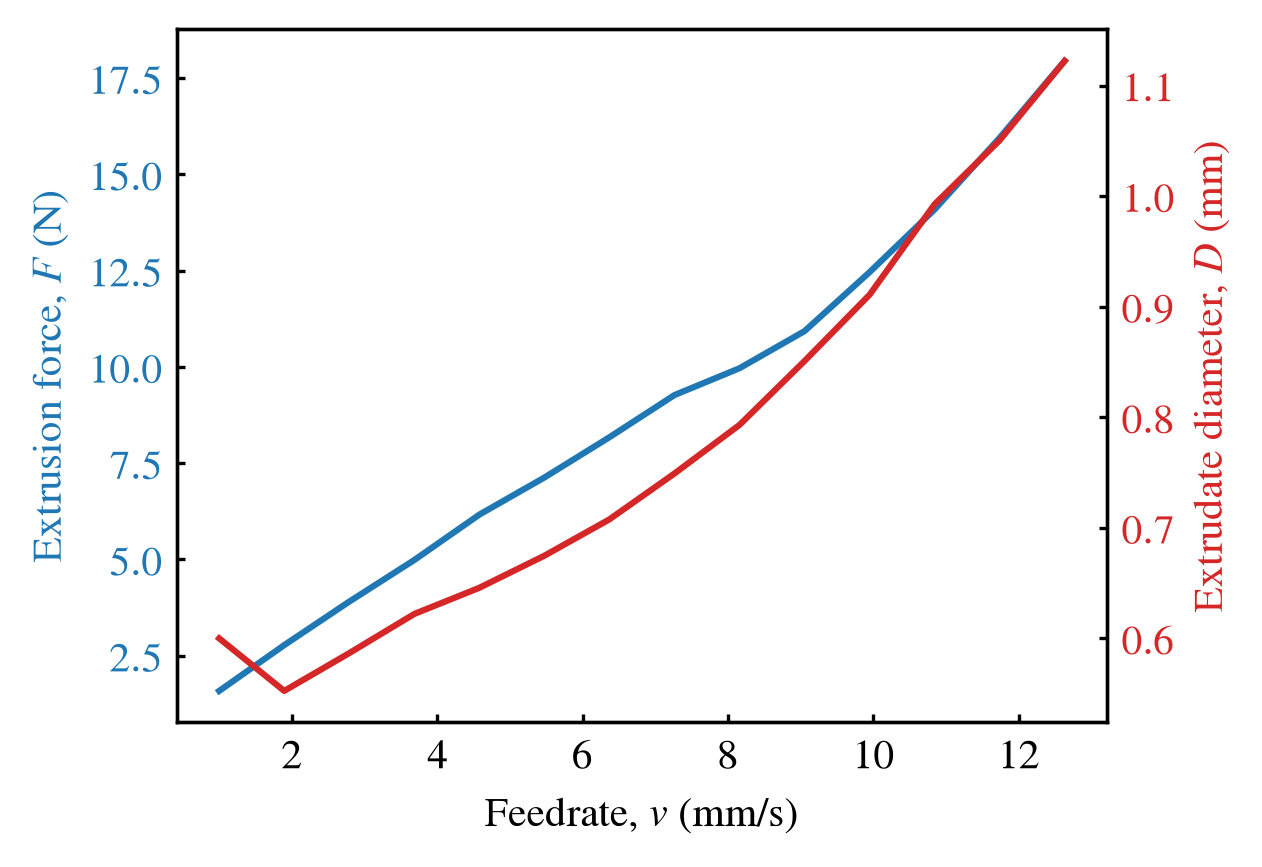

In [114]:
fig, ax1 = plt.subplots(figsize=(4, 3), dpi=300)

# 左 Y 轴
ax1.plot(fr_list, F_list, color='tab:blue', label='sin(x)')
ax1.set_xlabel('Feedrate, $v$ (mm/s)')
ax1.set_ylabel('Extrusion force, $F$ (N)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# 右 Y 轴
ax2 = ax1.twinx()
ax2.plot(fr_list, [d*0.0016 for d in D_list], color='tab:red', label='exp(x)')
ax2.set_ylabel('Extrudate diameter, $D$ (mm)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

In [8]:
df = pd.DataFrame({"FR": fr_list, "flowrate": [fr*2.4 for fr in fr_list], "F": F_list, "D": [d*0.02 for d in D_list]})
df["kF"] = df["F"].diff() / df["FR"].diff()
df["kD"] = df["D"].diff() / df["FR"].diff()
df

,FR,flowrate,F,D,kF,kD
0,2.130500,5.1132,6.917838,0.408120,NaN,NaN
1,2.695667,6.4696,8.173098,0.432693,2.221043,0.043480
2,3.260833,7.8260,9.511531,0.440518,2.368210,0.013845
3,3.826167,9.1828,10.894341,0.456967,2.446008,0.029096
4,4.391333,10.5392,12.290789,0.468965,2.470860,0.021229
5,4.956500,11.8956,13.772965,0.477357,2.622547,0.014849
6,5.521667,13.2520,15.233445,0.487997,2.584159,0.018826
7,6.087000,14.6088,16.709586,0.497955,2.611099,0.017614
8,6.652167,15.9652,18.198390,0.511596,2.634273,0.024137
9,7.217333,17.3216,20.046222,0.527023,3.269536,0.027297


In [74]:
def find_breakpoint_by_two_lines(x, y, min_points=4):
    """
    双线性拟合寻找拐点：
    遍历所有可能分割点，分别拟合低流速段和高流速段，
    选择总残差最小的分割点。
    两条直线的交点作为拐点。
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # 按 x 排序
    idx = np.argsort(x)
    x = x[idx]
    y = y[idx]

    best = None

    for split in range(min_points, len(x) - min_points + 1):
        x1, y1 = x[:split], y[:split]
        x2, y2 = x[split:], y[split:]

        # 左右两段分别线性拟合
        k1, b1 = np.polyfit(x1, y1, 1)
        k2, b2 = np.polyfit(x2, y2, 1)

        y1_fit = k1 * x1 + b1
        y2_fit = k2 * x2 + b2

        sse = np.sum((y1 - y1_fit) ** 2) + np.sum((y2 - y2_fit) ** 2)

        if best is None or sse < best["sse"]:
            best = {
                "split": split,
                "k1": k1,
                "b1": b1,
                "k2": k2,
                "b2": b2,
                "sse": sse
            }

    k1, b1 = best["k1"], best["b1"]
    k2, b2 = best["k2"], best["b2"]

    # 两条直线交点
    if abs(k1 - k2) < 1e-12:
        x_cross = np.nan
        y_cross = np.nan
    else:
        x_cross = (b2 - b1) / (k1 - k2)
        y_cross = k1 * x_cross + b1

    best["x_cross"] = x_cross
    best["y_cross"] = y_cross

    return best

inferred step length: 1506
number of steps: 20
Force breakpoint: 10.31 mm/s
Diameter breakpoint: 8.78 mm/s


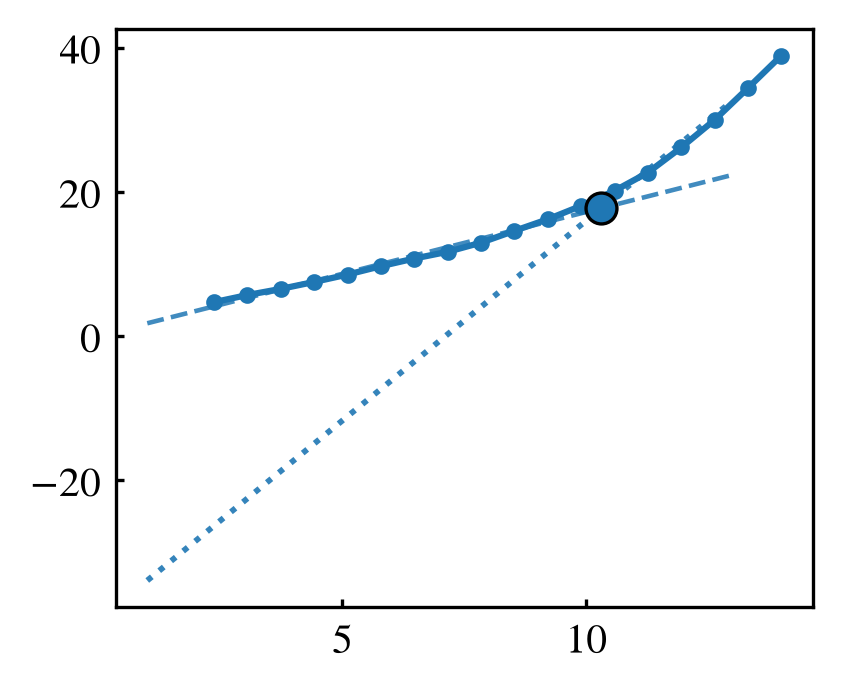

In [145]:
raw = pd.read_csv(r"G:\我的云端硬盘\Polymaker\008.知识产权\挤出力拐点\数据\20261104_143746_abs_0.4.csv")
cleaned_steps, data_clean, step_length = dc.clean_data(raw)

T_list, fr_list, F_list, D_list = [], [], [], []
for step in cleaned_steps:
    T = step["temperature_C"][int(0.2*step_length):].mean()
    fr = step["feedrate_mms"][int(0.2*step_length):].mean()
    F = step["extrusion_force_N"][int(0.2*step_length):].mean()
    D = step["die_diameter_px"][int(0.2*step_length):].mean()
    if fr < 2 or fr > 18:
        continue
    T_list.append(T)
    fr_list.append(fr)
    F_list.append(F)
    D_list.append(D)

fit = find_breakpoint_by_two_lines(fr_list, F_list)
fit_d = find_breakpoint_by_two_lines(fr_list, D_list)



k1, b1 = fit["k1"], fit["b1"]
k2, b2 = fit["k2"], fit["b2"]
x_cross = fit["x_cross"]
y_cross = fit["y_cross"]

# 画两条拟合直线
x_fit = np.linspace(1, 13, 300)
y_fit1 = k1 * x_fit + b1
y_fit2 = k2 * x_fit + b2


fig, ax = plt.subplots(figsize=(3, 2.5), dpi=300)

color = plt.cm.tab10(0)

ax.plot(fr_list, F_list, marker='o', color=color, markersize=3, label='Extrusion force, $F$ (N)')

ax.plot(
    x_fit,
    y_fit1,
    linestyle="--",
    color=color,
    linewidth=1.1,
    alpha=0.85,
)

ax.plot(
    x_fit,
    y_fit2,
    linestyle=":",
    color=color,
    linewidth=1.4,
    alpha=0.9,
)

# 标出拐点
ax.scatter(
    x_cross,
    y_cross,
    s=55,
    color=color,
    edgecolors="black",
    linewidths=0.8,
    zorder=5
)

print(f"Force breakpoint: {fit['x_cross']:.2f} mm/s")
print(f"Diameter breakpoint: {fit_d['x_cross']:.2f} mm/s")

In [116]:
find_breakpoint_by_two_lines(fr_list, F_list)

{'split': 8,
 'k1': np.float64(1.1233169567927193),
 'b1': np.float64(0.9145527676689795),
 'k2': np.float64(2.047814527447139),
 'b2': np.float64(-8.006929113660963),
 'sse': np.float64(0.1607868124135121),
 'x_cross': np.float64(9.650086884506072),
 'y_cross': np.float64(11.754658999557673)}

In [122]:
fr_list

[np.float64(2.7895),
 np.float64(3.684166666666667),
 np.float64(4.579),
 np.float64(5.4736666666666665),
 np.float64(6.368499999999998),
 np.float64(7.263166666666665),
 np.float64(8.15783333333333),
 np.float64(9.052666666666669),
 np.float64(9.947333333333333),
 np.float64(10.842166666666671),
 np.float64(11.736833333333333),
 np.float64(12.6315)]

In [104]:
F_list

[np.float64(5.742174362720403),
 np.float64(7.690515744265081),
 np.float64(9.646621764111204),
 np.float64(11.683125679530201),
 np.float64(13.693601085642317),
 np.float64(15.902395663519314),
 np.float64(17.56713108247423),
 np.float64(19.95382184819897),
 np.float64(22.379632927101202),
 np.float64(23.264828139261745)]